In [ ]:
!pip install pandas numpy matplotlib seaborn plotly openpyxl scikit-learn

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Updated_Cleaned_RIT_Dataset.xlsx to Updated_Cleaned_RIT_Dataset.xlsx


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

import warnings
warnings.filterwarnings("ignore")

sns.set(style="whitegrid")

In [ ]:
df = pd.read_excel("Updated_Cleaned_RIT_Dataset.xlsx")
df.head()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age_at_Signup,Signup_Month,Signup_Month_Name
0,2023-06-14 12:30:35,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Faria,2001-01-12,Female,Pakistan,Nwihs,Radiology,2024-03-11 12:01:41,Started,1080,2023-06-14 12:36:09,2022-11-03 18:30:39,22,6,June
1,2023-05-01 05:29:16,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Poojitha,2000-08-16,Female,India,Saint Louis University,Information Systems,2024-03-11 12:01:41,Started,1080,2023-05-01 06:08:21,2022-11-03 18:30:39,22,5,May
2,2023-04-09 20:35:08,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Emmanuel,2002-01-27,Male,United States,Illinois Institute Of Technology,Computer Science,2024-03-11 12:01:41,Started,1080,NaT,2022-11-03 18:30:39,21,4,April
3,2023-08-29 05:20:03,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Amrutha Varshini,1999-11-01,Female,United States,Saint Louis University,Information Systems,2024-03-11 12:01:41,Team Allocated,1070,2023-10-09 22:02:42,2022-11-03 18:30:39,23,8,August
4,2023-01-06 15:26:36,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Vinay Varshith,2000-04-19,Male,United States,Saint Louis University,Computer Science,2024-03-11 12:01:41,Started,1080,2023-01-06 15:40:10,2022-11-03 18:30:39,22,1,January


Data Cleaning

In [ ]:
df.tail()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age_at_Signup,Signup_Month,Signup_Month_Name
8257,2024-03-05 16:39:21,00000000-10GQ-RJHT-3G4S-BKGBY1,Freelance Mastery workshop,Event,2024-03-08 11:30:00,Selam,2006-10-14,Female,Ethiopia,Lideta Catholic Cathedral School,Computer Science,2024-03-11 12:03:14,Team Allocated,1070,2024-03-05 17:10:41,2024-03-08 14:00:00,17,3,March
8258,2024-03-06 15:58:47,00000000-10GQ-RJHT-3G4S-BKGBY1,Freelance Mastery workshop,Event,2024-03-08 11:30:00,Gowri Sailesh,1999-05-18,Male,United States,Saint Louis University,Information Systems,2024-03-11 12:03:14,Team Allocated,1070,2024-03-06 18:22:11,2024-03-08 14:00:00,24,3,March
8259,2024-02-29 15:02:31,00000000-10GQ-RJHT-3G4S-BKGBY1,Freelance Mastery workshop,Event,2024-03-08 11:30:00,Abiola,1999-03-16,Male,Nigeria,Tai Solarin University Of Education,Political Science,2024-03-11 12:03:14,Team Allocated,1070,2024-02-29 15:10:06,2024-03-08 14:00:00,25,2,February
8260,2023-12-23 03:53:12,00000000-10GQ-RJHT-3G4S-BKGBY1,Freelance Mastery workshop,Event,2024-03-08 11:30:00,venumadhavi,1997-06-05,Female,United States,Saint Louis University,Information Systems,2024-03-11 12:03:14,Team Allocated,1070,2024-02-27 06:48:47,2024-03-08 14:00:00,26,12,December
8261,2023-06-01 13:22:01,00000000-10GQ-RJHT-3G4S-BKGBY1,Freelance Mastery workshop,Event,2024-03-08 11:30:00,Prashanth Reddy,2000-11-30,Male,India,Saint Louis University,Artificial Intelligence,2024-03-11 12:03:14,Team Allocated,1070,2024-02-16 16:33:00,2024-03-08 14:00:00,22,6,June


In [ ]:
print(df.shape)

(8262, 19)


In [ ]:
print(df.columns)

Index(['Learner SignUp DateTime', 'Opportunity Id', 'Opportunity Name',
       'Opportunity Category', 'Opportunity End Date', 'First Name',
       'Date of Birth', 'Gender', 'Country', 'Institution Name',
       'Current/Intended Major', 'Entry created at', 'Status Description',
       'Status Code', 'Apply Date', 'Opportunity Start Date', 'Age_at_Signup',
       'Signup_Month', 'Signup_Month_Name'],
      dtype='object')


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8262 entries, 0 to 8261
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Learner SignUp DateTime  8262 non-null   datetime64[ns]
 1   Opportunity Id           8262 non-null   object        
 2   Opportunity Name         8262 non-null   object        
 3   Opportunity Category     8262 non-null   object        
 4   Opportunity End Date     7047 non-null   datetime64[ns]
 5   First Name               8262 non-null   object        
 6   Date of Birth            8262 non-null   datetime64[ns]
 7   Gender                   8262 non-null   object        
 8   Country                  8262 non-null   object        
 9   Institution Name         8262 non-null   object        
 10  Current/Intended Major   8262 non-null   object        
 11  Entry created at         8262 non-null   datetime64[ns]
 12  Status Description       8262 non-

In [ ]:
df.isnull().sum()

,0
Learner SignUp DateTime,0
Opportunity Id,0
Opportunity Name,0
Opportunity Category,0
Opportunity End Date,1215
First Name,0
Date of Birth,0
Gender,0
Country,0
Institution Name,0


In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
print(df.shape)

(8262, 19)


In [ ]:
date_columns = [
    'Learner SignUp DateTime',
    'Opportunity End Date',
    'Apply Date',
    'Opportunity Start Date'
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

In [ ]:
df['Age_at_Signup'] = pd.to_numeric(df['Age_at_Signup'], errors='coerce')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8262 entries, 0 to 8261
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Learner SignUp DateTime  8262 non-null   datetime64[ns]
 1   Opportunity Id           8262 non-null   object        
 2   Opportunity Name         8262 non-null   object        
 3   Opportunity Category     8262 non-null   object        
 4   Opportunity End Date     7047 non-null   datetime64[ns]
 5   First Name               8262 non-null   object        
 6   Date of Birth            8262 non-null   datetime64[ns]
 7   Gender                   8262 non-null   object        
 8   Country                  8262 non-null   object        
 9   Institution Name         8262 non-null   object        
 10  Current/Intended Major   8262 non-null   object        
 11  Entry created at         8262 non-null   datetime64[ns]
 12  Status Description       8262 non-

In [ ]:
df.head()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age_at_Signup,Signup_Month,Signup_Month_Name
0,2023-06-14 12:30:35,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Faria,2001-01-12,Female,Pakistan,Nwihs,Radiology,2024-03-11 12:01:41,Started,1080,2023-06-14 12:36:09,2022-11-03 18:30:39,22,6,June
1,2023-05-01 05:29:16,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Poojitha,2000-08-16,Female,India,Saint Louis University,Information Systems,2024-03-11 12:01:41,Started,1080,2023-05-01 06:08:21,2022-11-03 18:30:39,22,5,May
2,2023-04-09 20:35:08,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Emmanuel,2002-01-27,Male,United States,Illinois Institute Of Technology,Computer Science,2024-03-11 12:01:41,Started,1080,NaT,2022-11-03 18:30:39,21,4,April
3,2023-08-29 05:20:03,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Amrutha Varshini,1999-11-01,Female,United States,Saint Louis University,Information Systems,2024-03-11 12:01:41,Team Allocated,1070,2023-10-09 22:02:42,2022-11-03 18:30:39,23,8,August
4,2023-01-06 15:26:36,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Vinay Varshith,2000-04-19,Male,United States,Saint Louis University,Computer Science,2024-03-11 12:01:41,Started,1080,2023-01-06 15:40:10,2022-11-03 18:30:39,22,1,January


In [ ]:
df['Age_at_Signup'] = pd.to_numeric(df['Age_at_Signup'], errors='coerce').astype(int)

In [ ]:
df['Age_at_Signup'].dtype

dtype('int64')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
text_columns = [
    'Gender',
    'Country',
    'Institution Name',
    'Current/Intended Major'
]

for col in text_columns:
    df[col] = df[col].str.strip()

In [ ]:
df['Gender'] = df['Gender'].str.title()

In [ ]:
df.head()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age_at_Signup,Signup_Month,Signup_Month_Name
0,2023-06-14 12:30:35,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Faria,2001-01-12,Female,Pakistan,Nwihs,Radiology,2024-03-11 12:01:41,Started,1080,2023-06-14 12:36:09,2022-11-03 18:30:39,22,6,June
1,2023-05-01 05:29:16,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Poojitha,2000-08-16,Female,India,Saint Louis University,Information Systems,2024-03-11 12:01:41,Started,1080,2023-05-01 06:08:21,2022-11-03 18:30:39,22,5,May
2,2023-04-09 20:35:08,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Emmanuel,2002-01-27,Male,United States,Illinois Institute Of Technology,Computer Science,2024-03-11 12:01:41,Started,1080,NaT,2022-11-03 18:30:39,21,4,April
3,2023-08-29 05:20:03,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Amrutha Varshini,1999-11-01,Female,United States,Saint Louis University,Information Systems,2024-03-11 12:01:41,Team Allocated,1070,2023-10-09 22:02:42,2022-11-03 18:30:39,23,8,August
4,2023-01-06 15:26:36,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Vinay Varshith,2000-04-19,Male,United States,Saint Louis University,Computer Science,2024-03-11 12:01:41,Started,1080,2023-01-06 15:40:10,2022-11-03 18:30:39,22,1,January


In [ ]:
df['Gender'].unique()

array(['Female', 'Male', "Don'T Want To Specify", 'Other'], dtype=object)

In [ ]:
df['Country'].nunique()

70

In [ ]:
df['Age_at_Signup'].describe()

,Age_at_Signup
count,8262.000000
mean,23.518034
std,4.353366
min,13.000000
25%,21.000000
50%,23.000000
75%,25.000000
max,57.000000


In [ ]:
df['Age_at_Signup'].min()

13

In [ ]:
df = df[df['Age_at_Signup'] > 10]

In [ ]:
df['Age_at_Signup'].min()

13

In [ ]:
print(df.shape)

(8262, 19)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8262 entries, 0 to 8261
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Learner SignUp DateTime  8262 non-null   datetime64[ns]
 1   Opportunity Id           8262 non-null   object        
 2   Opportunity Name         8262 non-null   object        
 3   Opportunity Category     8262 non-null   object        
 4   Opportunity End Date     7047 non-null   datetime64[ns]
 5   First Name               8262 non-null   object        
 6   Date of Birth            8262 non-null   datetime64[ns]
 7   Gender                   8262 non-null   object        
 8   Country                  8262 non-null   object        
 9   Institution Name         8262 non-null   object        
 10  Current/Intended Major   8262 non-null   object        
 11  Entry created at         8262 non-null   datetime64[ns]
 12  Status Description       8262 non-

In [ ]:
df.describe(include='all')

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age_at_Signup,Signup_Month,Signup_Month_Name
count,8262,8262,8262,8262,7047,8262,8262,8262,8262,8262,8262,8262,8262,8262.000000,8023,3800,8262.000000,8262.000000,8262
unique,NaN,23,22,5,NaN,2949,NaN,4,70,1775,400,NaN,8,NaN,NaN,NaN,NaN,NaN,12
top,NaN,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Internship,NaN,Bhargavi,NaN,Male,United States,Saint Louis University,Information Systems,NaN,Rejected,NaN,NaN,NaN,NaN,NaN,January
freq,NaN,1374,1374,5237,NaN,40,NaN,4878,3769,4234,2074,NaN,3443,NaN,NaN,NaN,NaN,NaN,1737
mean,2023-09-28 06:51:03.614258176,NaN,NaN,NaN,2024-05-09 01:44:35.865758464,NaN,1999-10-11 04:10:37.908496768,NaN,NaN,NaN,NaN,2024-03-11 12:02:27.568385536,NaN,1052.275478,2023-11-23 14:30:19.746603520,2023-07-23 21:07:15.444473856,23.518034,5.566328,NaN
min,2023-01-05 16:32:31,NaN,NaN,NaN,2023-03-01 11:36:46,NaN,1966-08-08 00:00:00,NaN,NaN,NaN,NaN,2024-03-11 12:01:41,NaN,1010.000000,2022-10-05 14:28:56,2022-11-03 18:30:39,13.000000,1.000000,NaN
25%,2023-07-09 06:44:49,NaN,NaN,NaN,2024-03-11 18:00:00,NaN,1998-08-03 06:00:00,NaN,NaN,NaN,NaN,2024-03-11 12:02:04,NaN,1030.000000,2023-09-10 22:06:32.500000,2022-11-03 18:30:39,21.000000,2.000000,NaN
50%,2023-09-21 01:46:40,NaN,NaN,NaN,2024-03-11 18:00:00,NaN,2000-07-20 00:00:00,NaN,NaN,NaN,NaN,2024-03-11 12:02:27,NaN,1050.000000,2024-01-06 01:44:46,2024-01-08 03:30:46,23.000000,6.000000,NaN
75%,2024-01-10 05:33:28.249999872,NaN,NaN,NaN,2024-06-29 18:52:39,NaN,2001-12-17 00:00:00,NaN,NaN,NaN,NaN,2024-03-11 12:02:52,NaN,1070.000000,2024-02-02 22:15:34,2024-01-28 18:30:00,25.000000,8.000000,NaN
max,2024-03-11 10:43:44,NaN,NaN,NaN,2025-12-24 03:34:00,NaN,2011-02-17 00:00:00,NaN,NaN,NaN,NaN,2024-03-11 12:03:14,NaN,1120.000000,2024-03-11 11:07:38,2024-05-31 07:04:54,57.000000,12.000000,NaN


EXploratory Data Analysis

In [ ]:
#1 Gender Distribution Analysis
df['Gender'].value_counts()

,count
Gender,
Male,4878
Female,3366
Don'T Want To Specify,15
Other,3


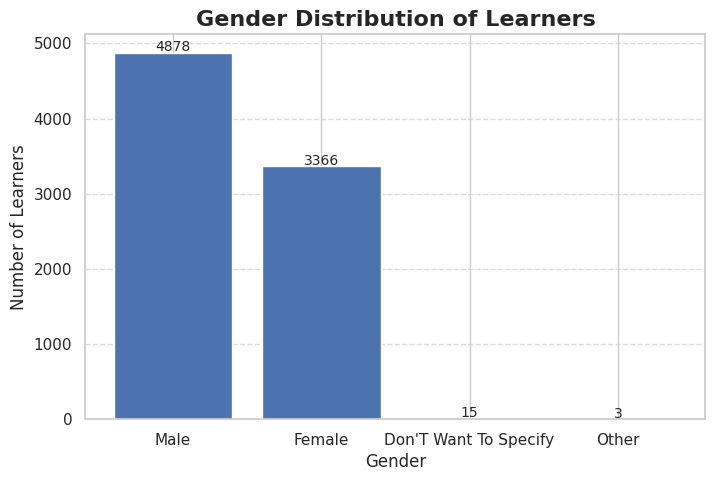

In [ ]:
# Count gender values
gender_counts = df['Gender'].value_counts()

# Create figure
plt.figure(figsize=(8,5))

# Plot bar chart
bars = plt.bar(
    gender_counts.index,
    gender_counts.values
)

# Add title and labels
plt.title('Gender Distribution of Learners', fontsize=16, fontweight='bold')
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Number of Learners', fontsize=12)

# Add value labels on bars
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 20,
        int(yval),
        ha='center',
        fontsize=10
    )

# Improve layout
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show graph
plt.show()

In [ ]:
#2 Country-wise Analysis
df['Country'].nunique()

70

In [ ]:
df['Country'].value_counts()

,count
Country,
United States,3769
India,2806
Nigeria,733
Ghana,258
Pakistan,219
...,...
Ireland,1
Libyan Arab Jamahiriya,1
Afghanistan,1


In [ ]:
df['Country'].value_counts().head(10)

,count
Country,
United States,3769
India,2806
Nigeria,733
Ghana,258
Pakistan,219
Bangladesh,59
Egypt,46
Ethiopia,38
Kenya,38


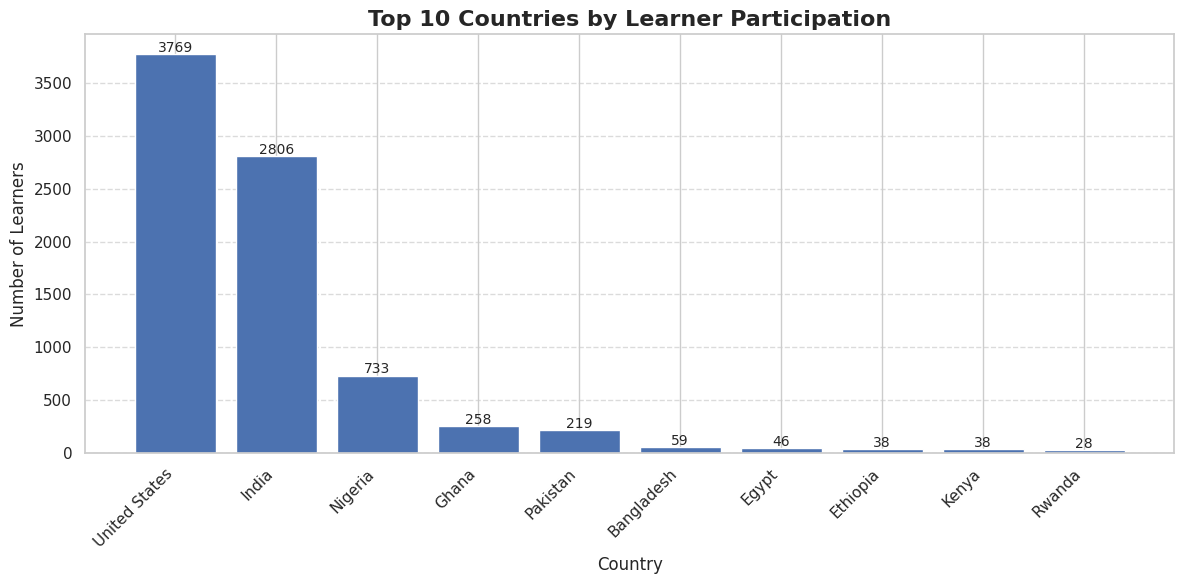

In [ ]:
# Top 10 countries
country_counts = df['Country'].value_counts().head(10)

# Create figure
plt.figure(figsize=(12,6))

# Plot bar chart
bars = plt.bar(
    country_counts.index,
    country_counts.values
)

# Title and labels
plt.title('Top 10 Countries by Learner Participation', fontsize=16, fontweight='bold')
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of Learners', fontsize=12)

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add values on bars
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 20,
        int(yval),
        ha='center',
        fontsize=10
    )

# Add grid
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Improve spacing
plt.tight_layout()

# Show graph
plt.show()

In [ ]:
#Opportunity Category Analysis
df['Opportunity Category'].value_counts()

,count
Opportunity Category,
Internship,5237
Course,1963
Event,524
Competition,411
Engagement,127


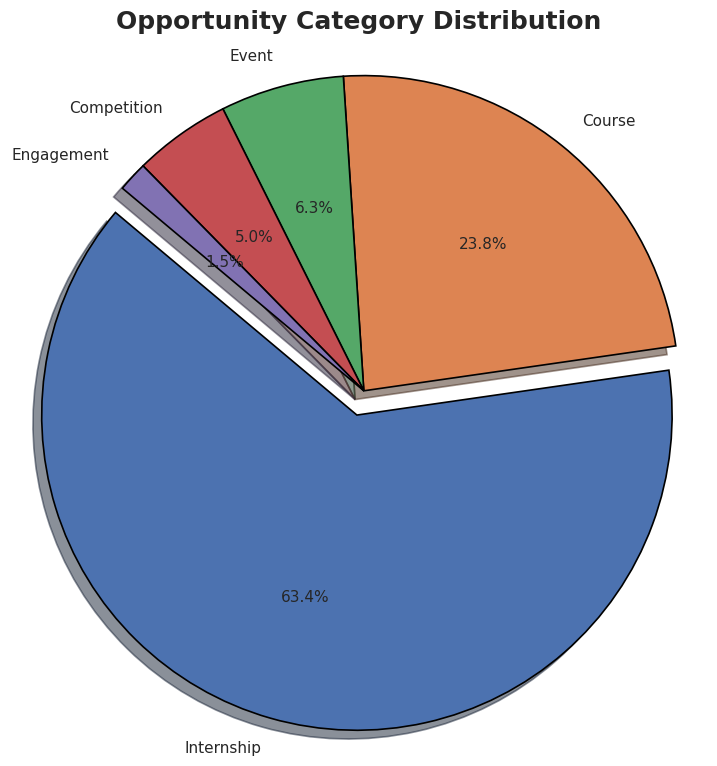

In [ ]:
#3 Count opportunity categories
category_counts = df['Opportunity Category'].value_counts()

# Create figure
plt.figure(figsize=(9,9))

# Explode largest slice slightly
explode = [0.08 if i == 0 else 0 for i in range(len(category_counts))]

# Create pie chart
plt.pie(
    category_counts.values,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    explode=explode,
    shadow=True,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1.2},
    textprops={'fontsize': 11}
)

# Add title
plt.title(
    'Opportunity Category Distribution',
    fontsize=18,
    fontweight='bold',
    pad=20
)

# Equal aspect ratio
plt.axis('equal')

# Show chart
plt.show()

In [ ]:
#4 Status Description Analysis
df['Status Description'].value_counts()

,count
Status Description,
Rejected,3443
Team Allocated,3162
Started,748
Dropped Out,596
Applied,103
Waitlisted,97
Withdraw,84
Rewards Award,29


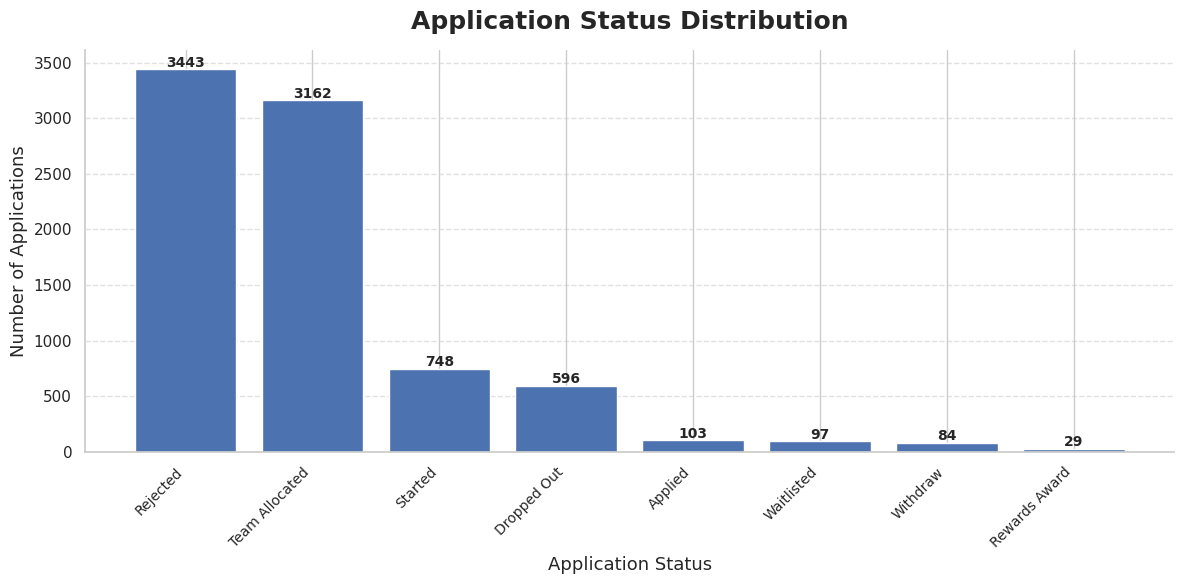

In [ ]:
# Count application statuses
status_counts = df['Status Description'].value_counts()

# Create figure
plt.figure(figsize=(12,6))

# Create bar chart
bars = plt.bar(
    status_counts.index,
    status_counts.values
)

# Add title and labels
plt.title(
    'Application Status Distribution',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel('Application Status', fontsize=13)
plt.ylabel('Number of Applications', fontsize=13)

# Rotate x labels
plt.xticks(rotation=45, ha='right', fontsize=10)

# Add values on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 20,
        int(yval),
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

# Add grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Remove unnecessary top/right borders
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Adjust layout
plt.tight_layout()

# Show chart
plt.show()

In [ ]:
#5 Age Distribution Analysis
df['Age_at_Signup'].describe()

,Age_at_Signup
count,8262.000000
mean,23.518034
std,4.353366
min,13.000000
25%,21.000000
50%,23.000000
75%,25.000000
max,57.000000


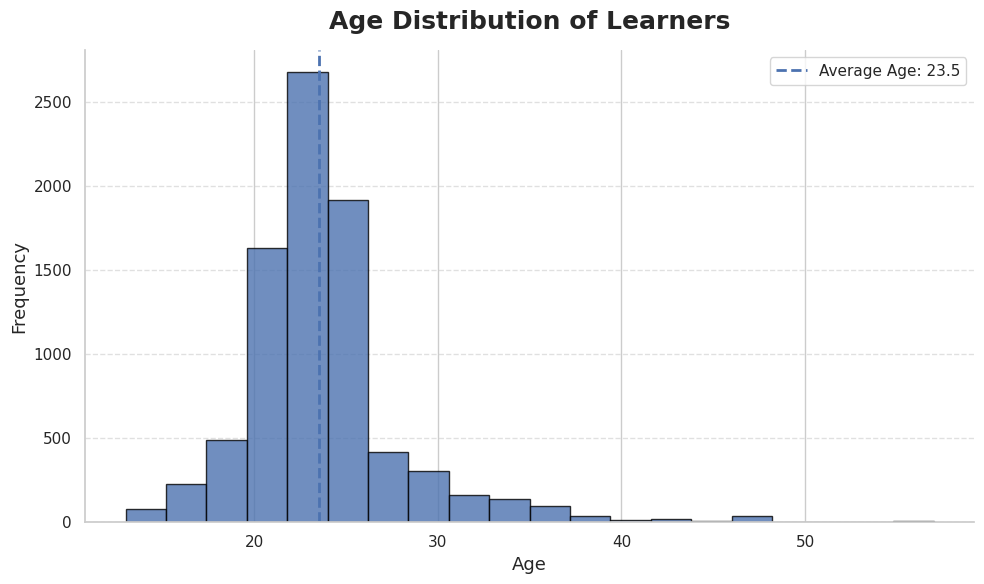

In [ ]:
# Create figure
plt.figure(figsize=(10,6))

# Create histogram
n, bins, patches = plt.hist(
    df['Age_at_Signup'],
    bins=20,
    edgecolor='black',
    alpha=0.8
)

# Add title and labels
plt.title(
    'Age Distribution of Learners',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel('Age', fontsize=13)
plt.ylabel('Frequency', fontsize=13)

# Add grid
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Add mean age line
mean_age = df['Age_at_Signup'].mean()

plt.axvline(
    mean_age,
    linestyle='dashed',
    linewidth=2,
    label=f'Average Age: {mean_age:.1f}'
)

# Add legend
plt.legend()

# Remove unnecessary borders
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Improve layout
plt.tight_layout()

# Show chart
plt.show()

In [ ]:
#6 Top Institutions Analysis
df['Institution Name'].value_counts()

,count
Institution Name,
Saint Louis University,4234
Illinois Institute Of Technology,148
Webster University,60
Kwame Nkrumah University Of Science And Technology,33
Srm University,32
...,...
Emperical College,1
Saint Louis University Madrid,1
Purdue,1


In [ ]:
df['Institution Name'].value_counts().head(10)

,count
Institution Name,
Saint Louis University,4234
Illinois Institute Of Technology,148
Webster University,60
Kwame Nkrumah University Of Science And Technology,33
Srm University,32
University Of Ibadan,26
Vishnu Institute Of Technology,25
Chandigarh University,24
Vellore Institute Of Technology,23


In [ ]:
df['Institution Name'].value_counts().head(30)

,count
Institution Name,
Saint Louis University,4234
Illinois Institute Of Technology,148
Webster University,60
Kwame Nkrumah University Of Science And Technology,33
Srm University,32
University Of Ibadan,26
Vishnu Institute Of Technology,25
Chandigarh University,24
Vellore Institute Of Technology,23


In [ ]:
df['Institution Name'] = df['Institution Name'].str.strip()

In [ ]:
df['Institution Name'].value_counts().head(30)

,count
Institution Name,
Saint Louis University,4234
Illinois Institute Of Technology,148
Webster University,60
Kwame Nkrumah University Of Science And Technology,33
Srm University,32
University Of Ibadan,26
Vishnu Institute Of Technology,25
Chandigarh University,24
Vellore Institute Of Technology,23


In [ ]:
df['Institution Name'] = df['Institution Name'].replace({
    'Saint Louis University,': 'Saint Louis University',
    'St Louis University': 'Saint Louis University',
    'Saint Louis Univeristy': 'Saint Louis University',
    'Saint Louis':'Saint Louis University',
    'St. Louis University':'Saint Louis University'

}) #Replace Variations

In [ ]:
df['Institution Name'].value_counts().head(30) #verify cleaning

,count
Institution Name,
Saint Louis University,4234
Illinois Institute Of Technology,148
Webster University,60
Kwame Nkrumah University Of Science And Technology,33
Srm University,32
University Of Ibadan,26
Vishnu Institute Of Technology,25
Chandigarh University,24
Vellore Institute Of Technology,23


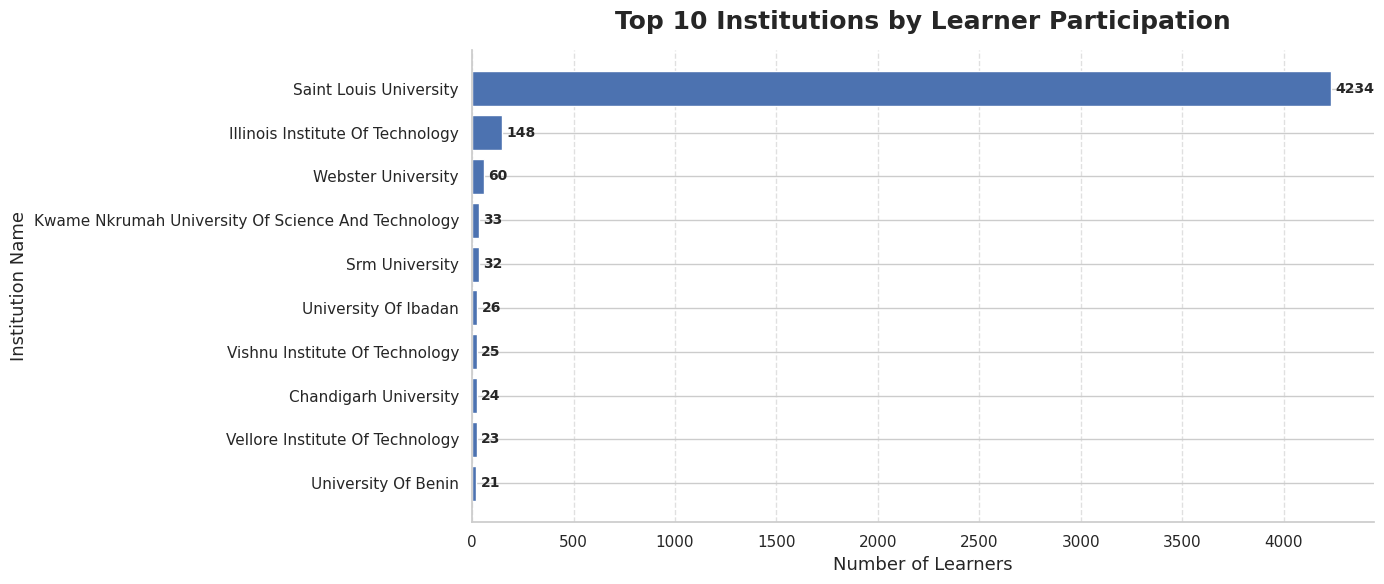

In [ ]:
# Top 10 institutions
institution_counts = df['Institution Name'].value_counts().head(10)

# Create figure
plt.figure(figsize=(14,6))

# Create horizontal bar chart
bars = plt.barh(
    institution_counts.index[::-1],
    institution_counts.values[::-1]
)

# Add title and labels
plt.title(
    'Top 10 Institutions by Learner Participation',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel('Number of Learners', fontsize=13)
plt.ylabel('Institution Name', fontsize=13)

# Add values on bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 20,
        bar.get_y() + bar.get_height()/2,
        int(width),
        va='center',
        fontsize=10,
        fontweight='bold'
    )

# Add grid
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Remove extra borders
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Improve spacing
plt.tight_layout()

# Show chart
plt.show()

In [ ]:
#7 Popular Majors Analysis
df['Current/Intended Major'].value_counts().head(10)

,count
Current/Intended Major,
Information Systems,2074
Computer Science,1022
Health Data Science,363
Cyber Security,319
Computer Information Systems,242
Computer Science and Information Systems,209
Computer Science and Engineering,207
Data Analytics,183
Public Health,128


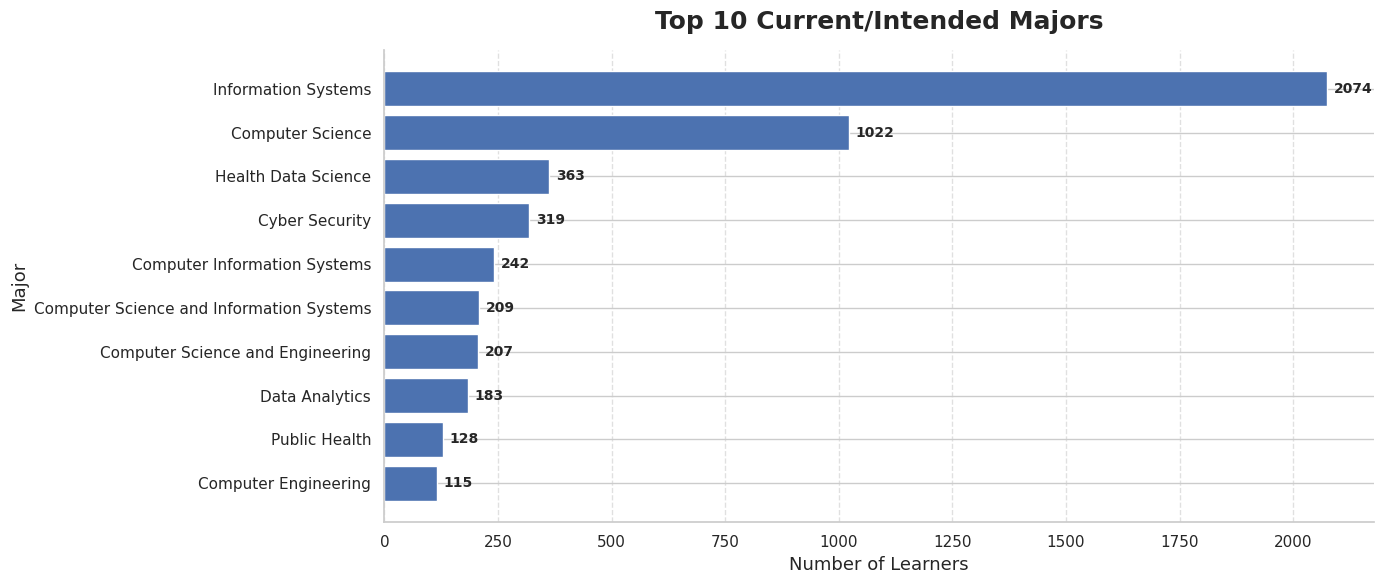

In [ ]:
# Top 10 majors
major_counts = df['Current/Intended Major'].value_counts().head(10)

# Create figure
plt.figure(figsize=(14,6))

# Create horizontal bar chart
bars = plt.barh(
    major_counts.index[::-1],
    major_counts.values[::-1]
)

# Add title and labels
plt.title(
    'Top 10 Current/Intended Majors',
    fontsize=18,
    fontweight='bold',
    pad=15
)

plt.xlabel('Number of Learners', fontsize=13)
plt.ylabel('Major', fontsize=13)

# Add values on bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 15,
        bar.get_y() + bar.get_height()/2,
        int(width),
        va='center',
        fontsize=10,
        fontweight='bold'
    )

# Add grid lines
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Remove unnecessary borders
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Improve layout
plt.tight_layout()

# Show chart
plt.show()

In [ ]:
#8 Monthly Signup Trend
df['Learner SignUp DateTime'] = pd.to_datetime(df['Learner SignUp DateTime'])

In [ ]:
df['Signup_Month'] = df['Learner SignUp DateTime'].dt.month

In [ ]:
print(df.columns)

Index(['Learner SignUp DateTime', 'Opportunity Id', 'Opportunity Name',
       'Opportunity Category', 'Opportunity End Date', 'First Name',
       'Date of Birth', 'Gender', 'Country', 'Institution Name',
       'Current/Intended Major', 'Entry created at', 'Status Description',
       'Status Code', 'Apply Date', 'Opportunity Start Date', 'Age_at_Signup',
       'Signup_Month', 'Signup_Month_Name'],
      dtype='object')


In [ ]:
df.head()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age_at_Signup,Signup_Month,Signup_Month_Name
0,2023-06-14 12:30:35,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Faria,2001-01-12,Female,Pakistan,Nwihs,Radiology,2024-03-11 12:01:41,Started,1080,2023-06-14 12:36:09,2022-11-03 18:30:39,22,6,June
1,2023-05-01 05:29:16,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Poojitha,2000-08-16,Female,India,Saint Louis University,Information Systems,2024-03-11 12:01:41,Started,1080,2023-05-01 06:08:21,2022-11-03 18:30:39,22,5,May
2,2023-04-09 20:35:08,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Emmanuel,2002-01-27,Male,United States,Illinois Institute Of Technology,Computer Science,2024-03-11 12:01:41,Started,1080,NaT,2022-11-03 18:30:39,21,4,April
3,2023-08-29 05:20:03,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Amrutha Varshini,1999-11-01,Female,United States,Saint Louis University,Information Systems,2024-03-11 12:01:41,Team Allocated,1070,2023-10-09 22:02:42,2022-11-03 18:30:39,23,8,August
4,2023-01-06 15:26:36,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Vinay Varshith,2000-04-19,Male,United States,Saint Louis University,Computer Science,2024-03-11 12:01:41,Started,1080,2023-01-06 15:40:10,2022-11-03 18:30:39,22,1,January


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8262 entries, 0 to 8261
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Learner SignUp DateTime  8262 non-null   datetime64[ns]
 1   Opportunity Id           8262 non-null   object        
 2   Opportunity Name         8262 non-null   object        
 3   Opportunity Category     8262 non-null   object        
 4   Opportunity End Date     7047 non-null   datetime64[ns]
 5   First Name               8262 non-null   object        
 6   Date of Birth            8262 non-null   datetime64[ns]
 7   Gender                   8262 non-null   object        
 8   Country                  8262 non-null   object        
 9   Institution Name         8262 non-null   object        
 10  Current/Intended Major   8262 non-null   object        
 11  Entry created at         8262 non-null   datetime64[ns]
 12  Status Description       8262 non-

In [ ]:
df['Signup_Month_Name'] = df['Learner SignUp DateTime'].dt.month_name()

In [ ]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

In [ ]:
monthly_signup = df['Signup_Month_Name'].value_counts().reindex(month_order)

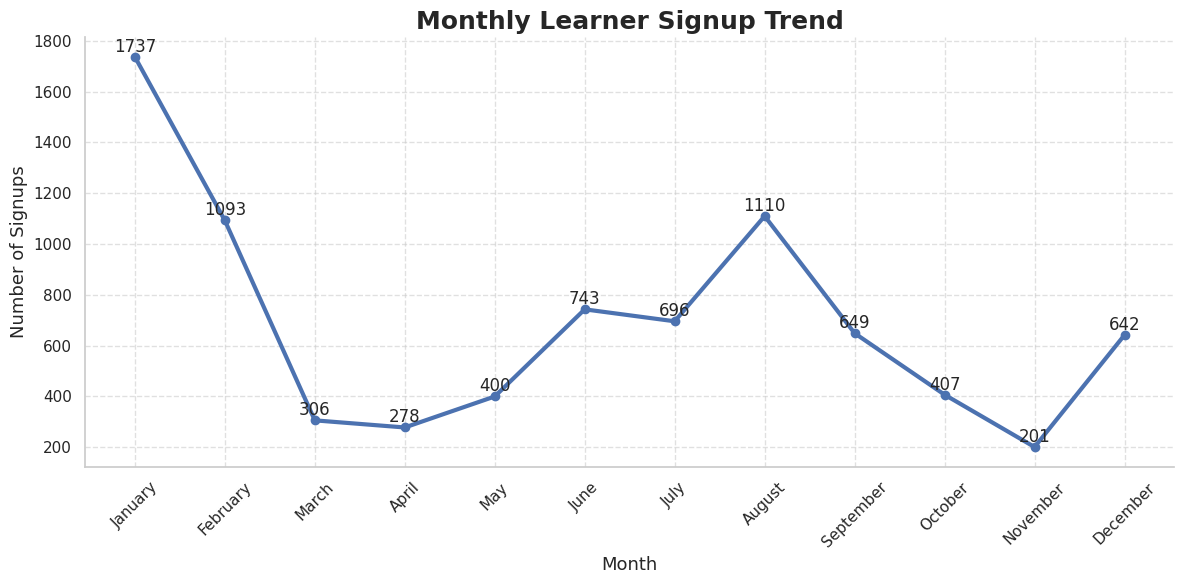

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_signup.index,
    monthly_signup.values,
    marker='o',
    linewidth=3
)

plt.title(
    'Monthly Learner Signup Trend',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('Month', fontsize=13)
plt.ylabel('Number of Signups', fontsize=13)

plt.xticks(rotation=45)

# Add values
for x, y in zip(monthly_signup.index, monthly_signup.values):
    plt.text(x, y + 20, int(y), ha='center')

plt.grid(True, linestyle='--', alpha=0.6)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.show()

In [ ]:
#Advanced EDA
#1 Gender vs Opportunity Category
gender_category = pd.crosstab(
    df['Gender'],
    df['Opportunity Category']
)

#gender_category

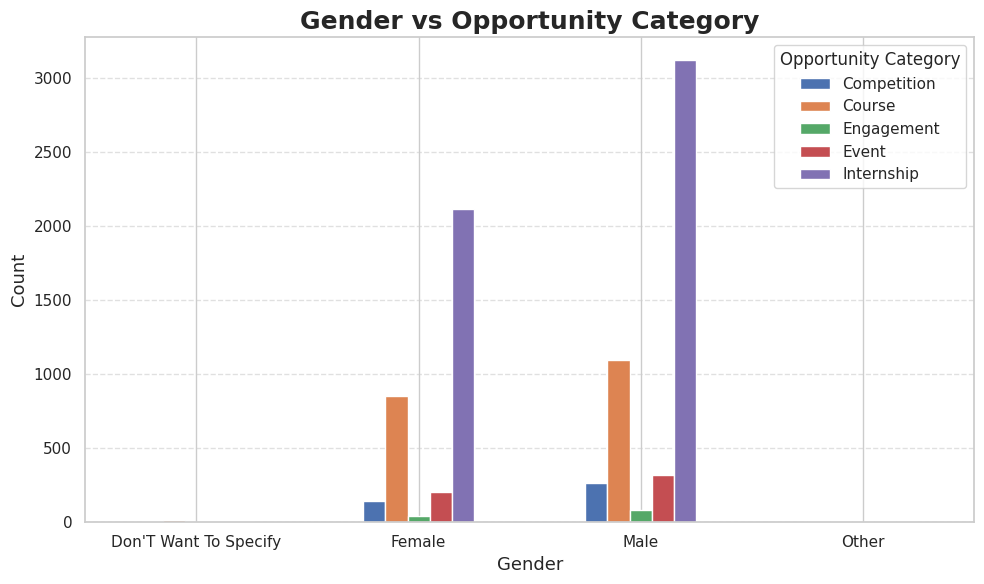

In [ ]:
gender_category.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title(
    'Gender vs Opportunity Category',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('Gender', fontsize=13)
plt.ylabel('Count', fontsize=13)

plt.xticks(rotation=0)

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()

plt.show()

In [ ]:
#2 Average Age by Gender
df.groupby('Gender')['Age_at_Signup'].mean()

,Age_at_Signup
Gender,
Don'T Want To Specify,23.800000
Female,23.393642
Male,23.602091
Other,25.000000


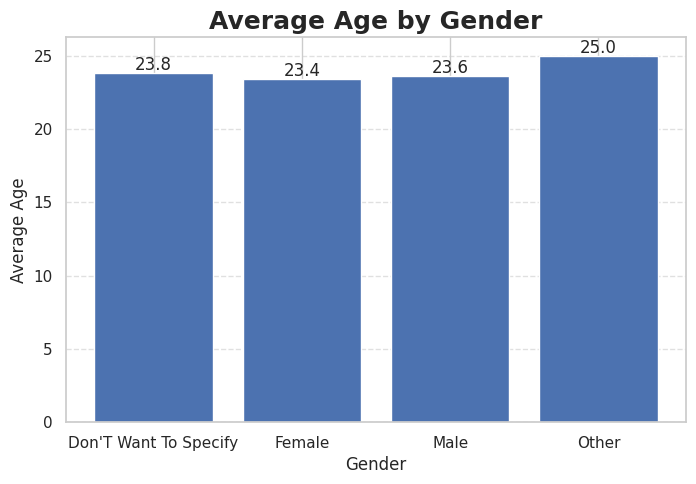

In [ ]:
avg_age = df.groupby('Gender')['Age_at_Signup'].mean()

plt.figure(figsize=(8,5))

bars = plt.bar(
    avg_age.index,
    avg_age.values
)

plt.title(
    'Average Age by Gender',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('Gender')
plt.ylabel('Average Age')

# Add values
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.2,
        round(yval,1),
        ha='center'
    )

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

In [ ]:
#3 Top Opportunity Names
df['Opportunity Name'].value_counts().head(10)

,count
Opportunity Name,
Career Essentials: Getting Started with Your Professional Journey,1374
Data Visualization,954
Project Management,805
Health Care Management,754
Digital Marketing,537
Data Visualization Associate,535
Business Consulting,464
Project Management Associate,461
Innovation & Entrepreneurship,405


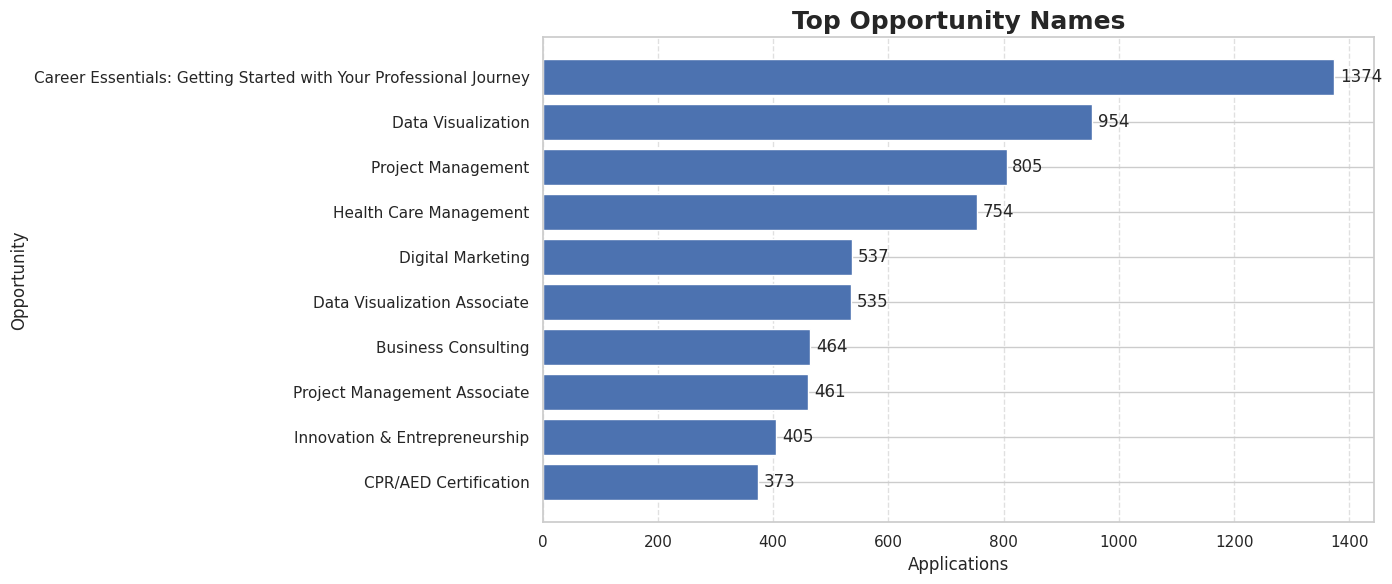

In [ ]:
top_opportunities = df['Opportunity Name'].value_counts().head(10)

plt.figure(figsize=(14,6))

bars = plt.barh(
    top_opportunities.index[::-1],
    top_opportunities.values[::-1]
)

plt.title(
    'Top Opportunity Names',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('Applications')
plt.ylabel('Opportunity')

# Add values
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 10,
        bar.get_y() + bar.get_height()/2,
        int(width),
        va='center'
    )

plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()

plt.show()

In [ ]:
#4 Correlation Analysis
numeric_df = df.select_dtypes(include=['int64', 'int32', 'float64'])

numeric_df.corr()

,Status Code,Age_at_Signup,Signup_Month
Status Code,1.000000,-0.041239,0.091519
Age_at_Signup,-0.041239,1.000000,-0.013869
Signup_Month,0.091519,-0.013869,1.000000


In [ ]:
corr_matrix = numeric_df.corr()

print(corr_matrix)

               Status Code  Age_at_Signup  Signup_Month
Status Code       1.000000      -0.041239      0.091519
Age_at_Signup    -0.041239       1.000000     -0.013869
Signup_Month      0.091519      -0.013869      1.000000


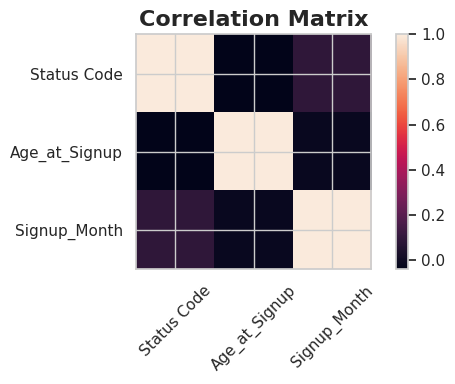

In [ ]:
corr_matrix = numeric_df.corr()

plt.figure(figsize=(6,4))

plt.imshow(corr_matrix)

plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title(
    'Correlation Matrix',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()

plt.show()

In [ ]:
df.head()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age_at_Signup,Signup_Month,Signup_Month_Name
0,2023-06-14 12:30:35,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Faria,2001-01-12,Female,Pakistan,Nwihs,Radiology,2024-03-11 12:01:41,Started,1080,2023-06-14 12:36:09,2022-11-03 18:30:39,22,6,June
1,2023-05-01 05:29:16,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Poojitha,2000-08-16,Female,India,Saint Louis University,Information Systems,2024-03-11 12:01:41,Started,1080,2023-05-01 06:08:21,2022-11-03 18:30:39,22,5,May
2,2023-04-09 20:35:08,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Emmanuel,2002-01-27,Male,United States,Illinois Institute Of Technology,Computer Science,2024-03-11 12:01:41,Started,1080,NaT,2022-11-03 18:30:39,21,4,April
3,2023-08-29 05:20:03,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Amrutha Varshini,1999-11-01,Female,United States,Saint Louis University,Information Systems,2024-03-11 12:01:41,Team Allocated,1070,2023-10-09 22:02:42,2022-11-03 18:30:39,23,8,August
4,2023-01-06 15:26:36,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Vinay Varshith,2000-04-19,Male,United States,Saint Louis University,Computer Science,2024-03-11 12:01:41,Started,1080,2023-01-06 15:40:10,2022-11-03 18:30:39,22,1,January


In [ ]:
df.to_excel('Updated_Cleaned_RIT_Dataset.xlsx', index=False)

In [ ]:
from google.colab import files

files.download('Updated_Cleaned_RIT_Dataset.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8262 entries, 0 to 8261
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Learner SignUp DateTime  8262 non-null   datetime64[ns]
 1   Opportunity Id           8262 non-null   object        
 2   Opportunity Name         8262 non-null   object        
 3   Opportunity Category     8262 non-null   object        
 4   Opportunity End Date     7047 non-null   datetime64[ns]
 5   First Name               8262 non-null   object        
 6   Date of Birth            8262 non-null   datetime64[ns]
 7   Gender                   8262 non-null   object        
 8   Country                  8262 non-null   object        
 9   Institution Name         8262 non-null   object        
 10  Current/Intended Major   8262 non-null   object        
 11  Entry created at         8262 non-null   datetime64[ns]
 12  Status Description       8262 non-